In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import os

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [2]:
(x_train, _), (_, _) = keras.datasets.fashion_mnist.load_data()

x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5

x_train = np.expand_dims(x_train, axis=-1)

print("Dataset shape:", x_train.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Dataset shape: (60000, 28, 28, 1)


In [3]:
def build_broken_generator():

    model = keras.Sequential(name="Broken_Generator")

    model.add(layers.Dense(7 * 7 * 64, input_shape=(100,)))
    model.add(layers.LeakyReLU(0.2))

    model.add(layers.Reshape((7, 7, 64)))

    # No Batch Normalization
    model.add(
        layers.Conv2DTranspose(
            32,
            kernel_size=4,
            strides=2,
            padding="same"
        )
    )
    model.add(layers.LeakyReLU(0.2))

    model.add(
        layers.Conv2DTranspose(
            1,
            kernel_size=4,
            strides=2,
            padding="same",
            activation="tanh"
        )
    )

    return model


broken_generator = build_broken_generator()
broken_generator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Broken_Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 3136)           │       316,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 32)     │        32,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │           513 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 350,049 (1.34 MB)

 Trainable params: 350,049 (1.34 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
def build_discriminator():

    model = keras.Sequential(name="Discriminator")

    model.add(
        layers.Conv2D(
            64,
            kernel_size=4,
            strides=2,
            padding="same",
            input_shape=(28, 28, 1)
        )
    )
    model.add(layers.LeakyReLU(0.2))

    model.add(
        layers.Conv2D(
            128,
            kernel_size=4,
            strides=2,
            padding="same"
        )
    )
    model.add(layers.LeakyReLU(0.2))

    model.add(layers.Flatten())
    model.add(layers.Dense(1))

    return model


discriminator = build_discriminator()
discriminator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
cross_entropy = keras.losses.BinaryCrossentropy(from_logits=True)

generator_optimizer = keras.optimizers.Adam(
    learning_rate=0.01,
    beta_1=0.5
)

discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=0.01,
    beta_1=0.5
)

In [6]:
@tf.function
def train_step(images):

    noise = tf.random.normal([tf.shape(images)[0], 100])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        generated_images = broken_generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = cross_entropy(
            tf.ones_like(fake_output),
            fake_output
        )

        real_loss = cross_entropy(
            tf.ones_like(real_output),
            real_output
        )

        fake_loss = cross_entropy(
            tf.zeros_like(fake_output),
            fake_output
        )

        disc_loss = real_loss + fake_loss

    gradients_of_generator = gen_tape.gradient(
        gen_loss,
        broken_generator.trainable_variables
    )

    gradients_of_discriminator = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            gradients_of_generator,
            broken_generator.trainable_variables
        )
    )

    discriminator_optimizer.apply_gradients(
        zip(
            gradients_of_discriminator,
            discriminator.trainable_variables
        )
    )

    return gen_loss, disc_loss

In [7]:
BATCH_SIZE = 128

dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(60000).batch(BATCH_SIZE)

In [8]:
seed = tf.random.normal([16, 100])

def generate_and_save_images(model, epoch, filename):

    predictions = model(seed, training=False)

    predictions = (predictions + 1) / 2.0

    fig = plt.figure(figsize=(6, 6))

    for i in range(16):
        plt.subplot(4, 4, i + 1)
        plt.imshow(predictions[i, :, :, 0], cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.savefig(filename)
    plt.show()

    plt.close()

Epoch 1/20 | Generator Loss: 13.0994 | Discriminator Loss: 0.0045


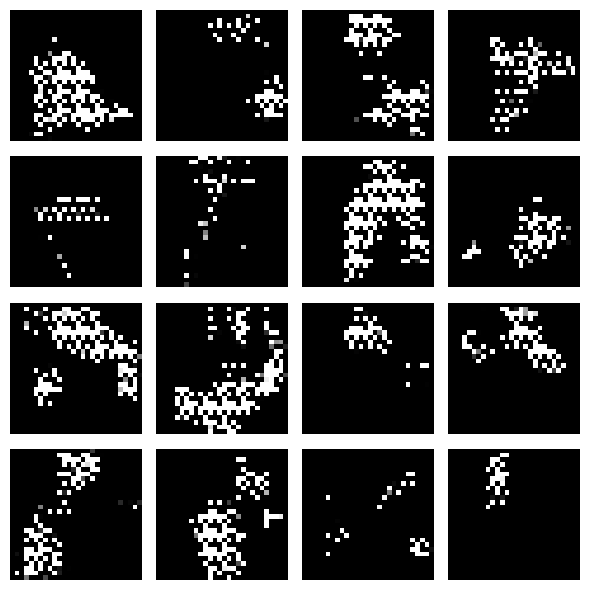

Epoch 2/20 | Generator Loss: 10.2248 | Discriminator Loss: 0.0002


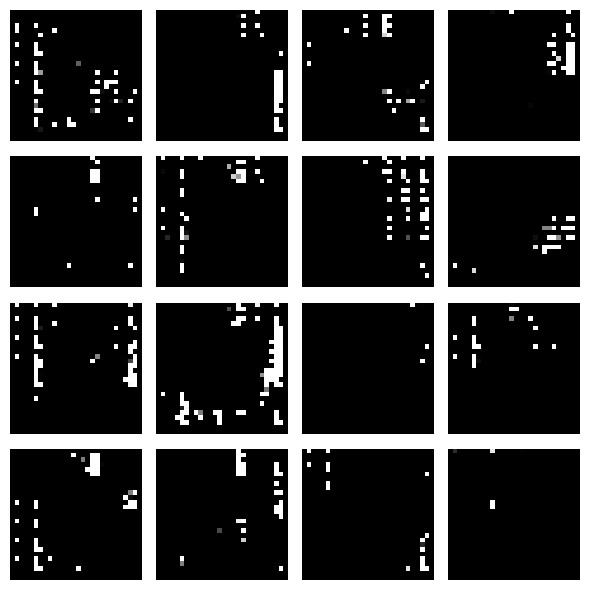

Epoch 3/20 | Generator Loss: 9.6584 | Discriminator Loss: 0.0002


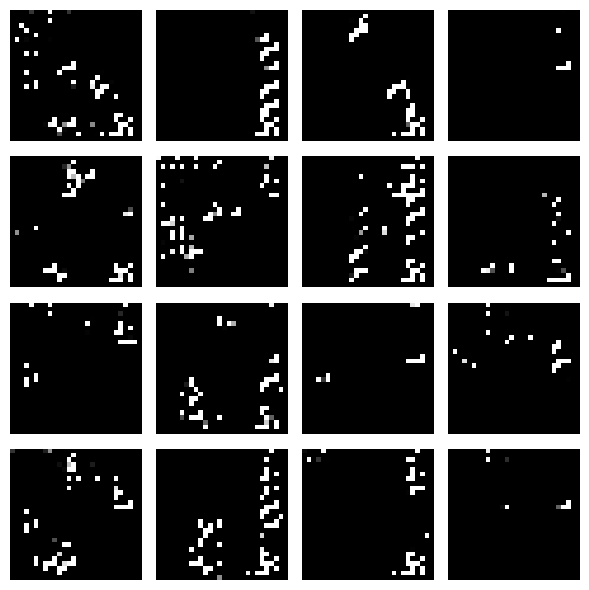

Epoch 4/20 | Generator Loss: 80.2284 | Discriminator Loss: 0.0000


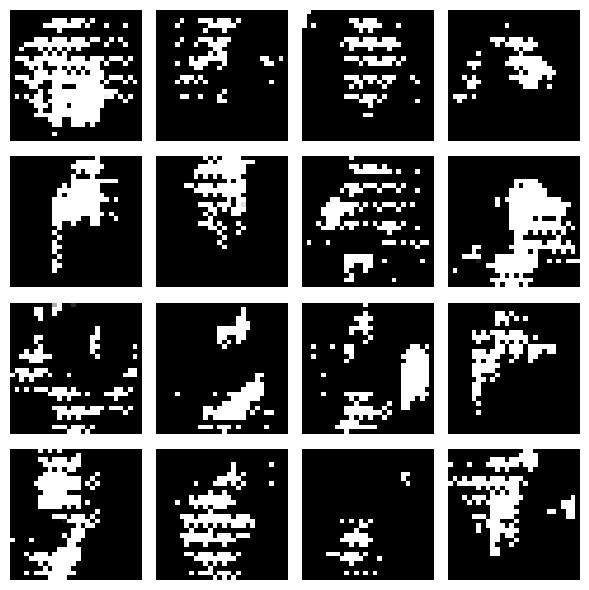

Epoch 5/20 | Generator Loss: 76.1381 | Discriminator Loss: 0.0000


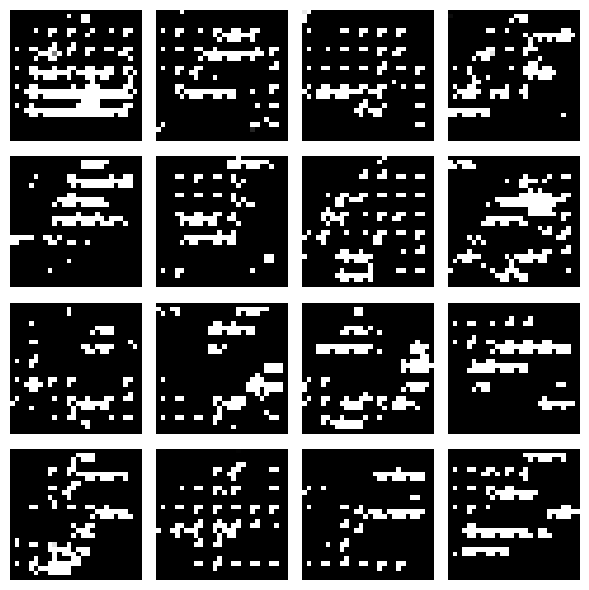

Epoch 6/20 | Generator Loss: 145.9386 | Discriminator Loss: 0.1110


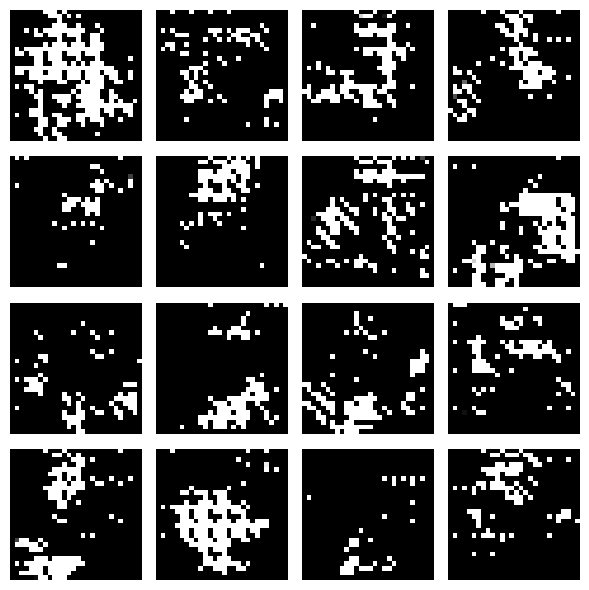

Epoch 7/20 | Generator Loss: 85.7590 | Discriminator Loss: 2.2768


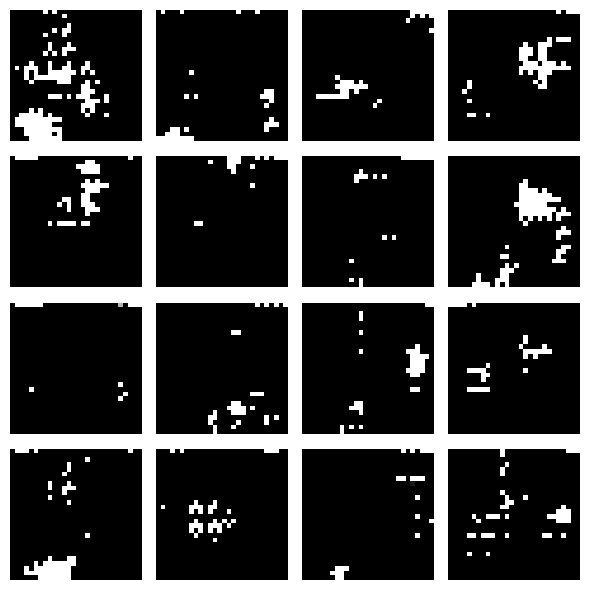

Epoch 8/20 | Generator Loss: 58.0562 | Discriminator Loss: 0.0000


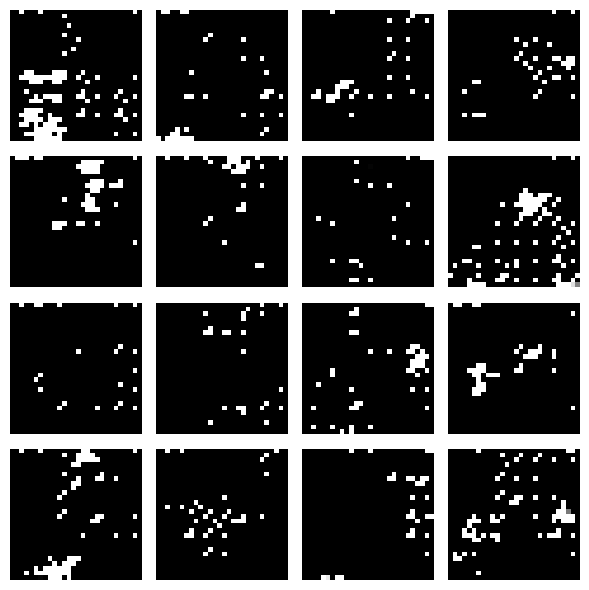

Epoch 9/20 | Generator Loss: 130.4639 | Discriminator Loss: 0.0000


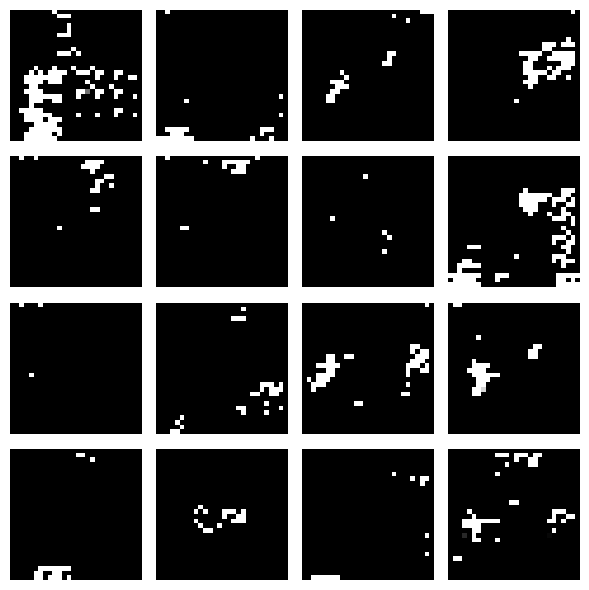

Epoch 10/20 | Generator Loss: 140.9675 | Discriminator Loss: 0.0000


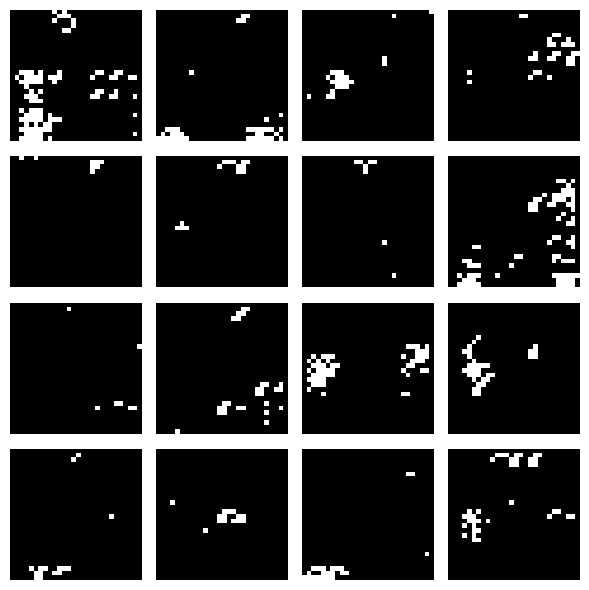

Epoch 11/20 | Generator Loss: 137.9990 | Discriminator Loss: 0.0000


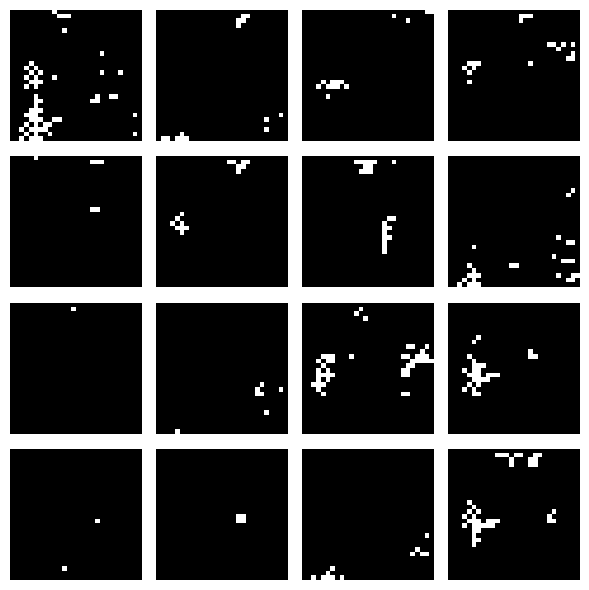

Epoch 12/20 | Generator Loss: 63.9603 | Discriminator Loss: 0.0000


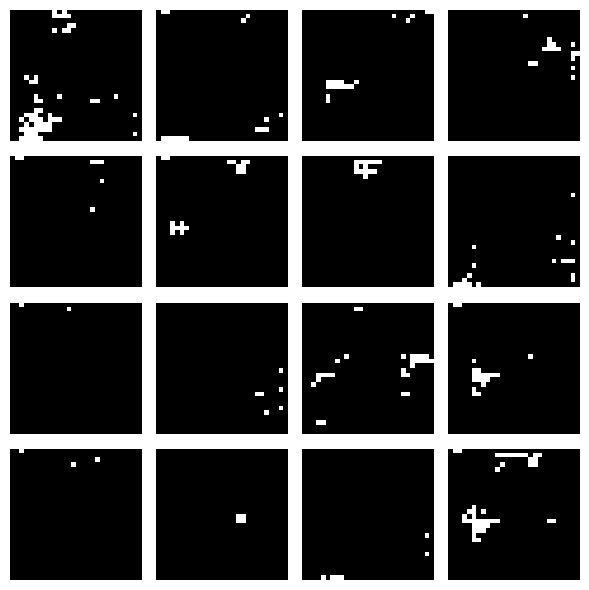

Epoch 13/20 | Generator Loss: 14570.6328 | Discriminator Loss: 2582.0825


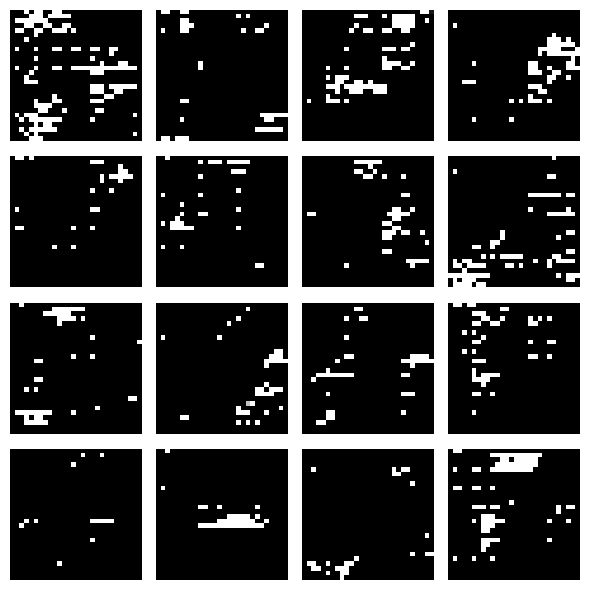

Epoch 14/20 | Generator Loss: 344.4651 | Discriminator Loss: 0.0474


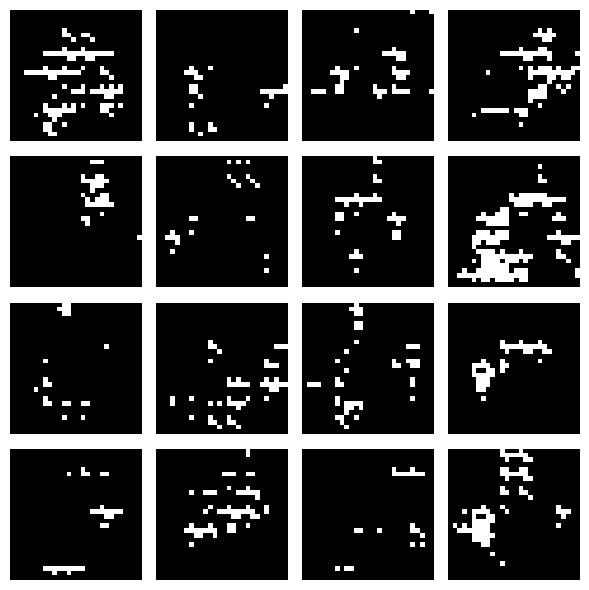

Epoch 15/20 | Generator Loss: 357.4767 | Discriminator Loss: 0.5493


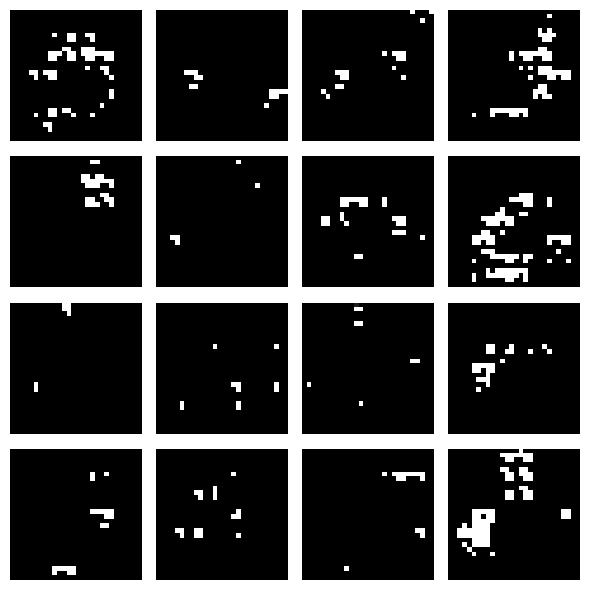

Epoch 16/20 | Generator Loss: 434.6710 | Discriminator Loss: 0.0000


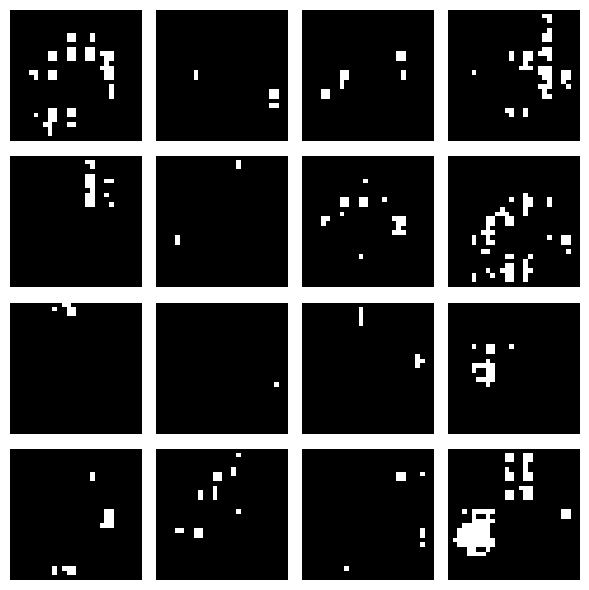

Epoch 17/20 | Generator Loss: 336.9868 | Discriminator Loss: 0.0000


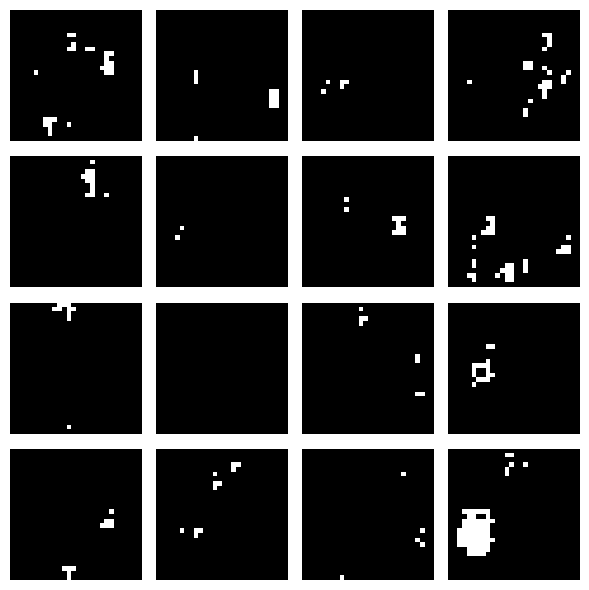

Epoch 18/20 | Generator Loss: 257.2515 | Discriminator Loss: 0.0000


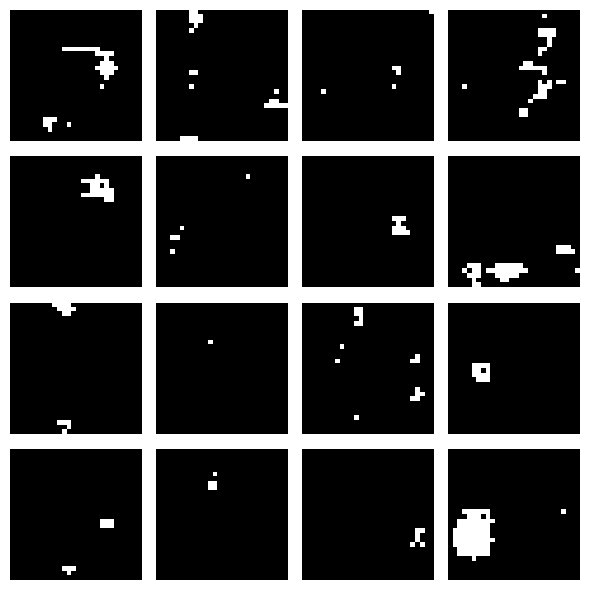

Epoch 19/20 | Generator Loss: 117.0099 | Discriminator Loss: 1.5213


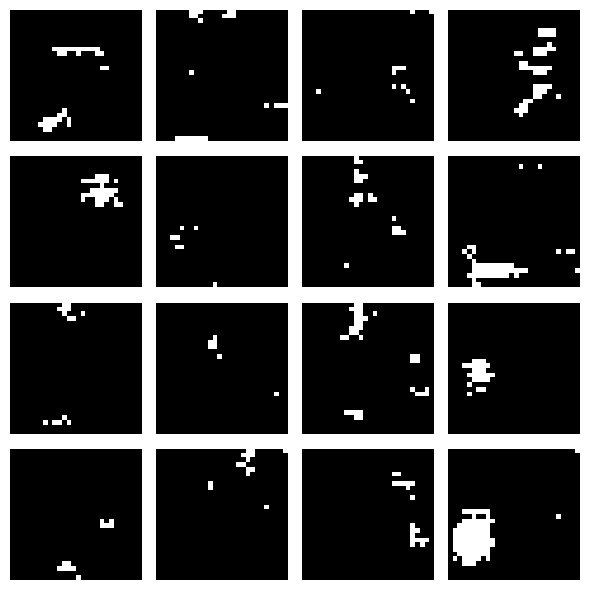

Epoch 20/20 | Generator Loss: 215.3708 | Discriminator Loss: 0.0000


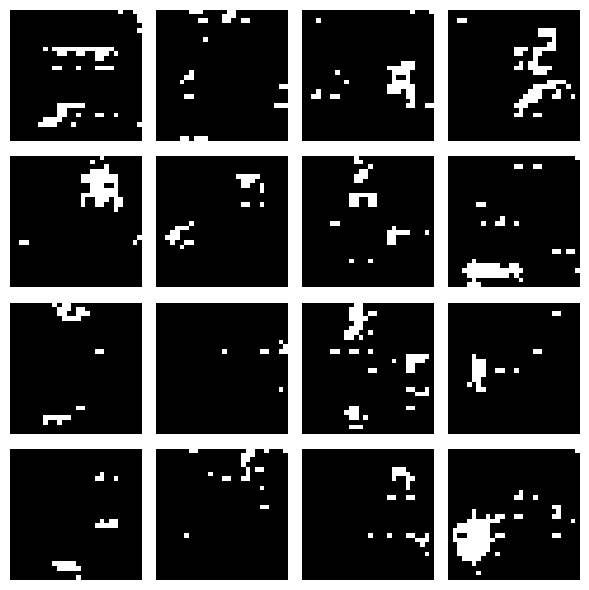

In [9]:
EPOCHS = 20

os.makedirs("broken_outputs", exist_ok=True)

for epoch in range(EPOCHS):

    for image_batch in dataset:
        g_loss, d_loss = train_step(image_batch)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"| Generator Loss: {g_loss:.4f} "
        f"| Discriminator Loss: {d_loss:.4f}"
    )

    generate_and_save_images(
        broken_generator,
        epoch + 1,
        f"broken_outputs/epoch_{epoch+1}.png"
    )

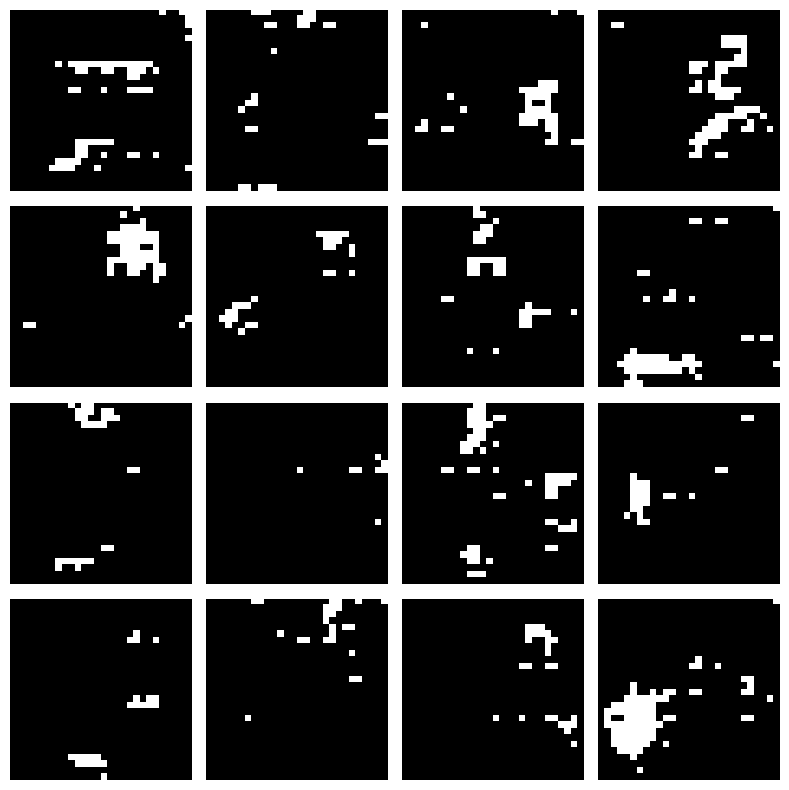

In [10]:
final_broken = broken_generator(seed, training=False)

final_broken = (final_broken + 1) / 2.0

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(final_broken[i, :, :, 0], cmap="gray")
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "mode_collapse_before.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [11]:
def build_fixed_generator():

    model = keras.Sequential(name="Fixed_Generator")

    model.add(layers.Dense(7 * 7 * 128, input_shape=(100,)))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))

    model.add(layers.Reshape((7, 7, 128)))

    model.add(
        layers.Conv2DTranspose(
            64,
            kernel_size=4,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))

    model.add(
        layers.Conv2DTranspose(
            1,
            kernel_size=4,
            strides=2,
            padding="same",
            activation="tanh"
        )
    )

    return model


fixed_generator = build_fixed_generator()

fixed_generator.summary()

Model: "Fixed_Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 14, 14, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 28, 28, 1)      │         1,025 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 790,977 (3.02 MB)

 Trainable params: 778,305 (2.97 MB)

 Non-trainable params: 12,672 (49.50 KB)

In [12]:
fixed_discriminator = build_discriminator()

In [13]:
fixed_generator_optimizer = keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

fixed_discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

In [14]:
@tf.function
def fixed_train_step(images):

    noise = tf.random.normal([tf.shape(images)[0], 100])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        generated_images = fixed_generator(
            noise,
            training=True
        )

        real_output = fixed_discriminator(
            images,
            training=True
        )

        fake_output = fixed_discriminator(
            generated_images,
            training=True
        )

        # Label smoothing
        real_labels = tf.ones_like(real_output) * 0.9
        fake_labels = tf.zeros_like(fake_output)

        gen_loss = cross_entropy(
            tf.ones_like(fake_output),
            fake_output
        )

        real_loss = cross_entropy(
            real_labels,
            real_output
        )

        fake_loss = cross_entropy(
            fake_labels,
            fake_output
        )

        disc_loss = real_loss + fake_loss

    gen_gradients = gen_tape.gradient(
        gen_loss,
        fixed_generator.trainable_variables
    )

    disc_gradients = disc_tape.gradient(
        disc_loss,
        fixed_discriminator.trainable_variables
    )

    fixed_generator_optimizer.apply_gradients(
        zip(
            gen_gradients,
            fixed_generator.trainable_variables
        )
    )

    fixed_discriminator_optimizer.apply_gradients(
        zip(
            disc_gradients,
            fixed_discriminator.trainable_variables
        )
    )

    return gen_loss, disc_loss

Epoch 1/20 | Generator Loss: 0.8559 | Discriminator Loss: 1.2098


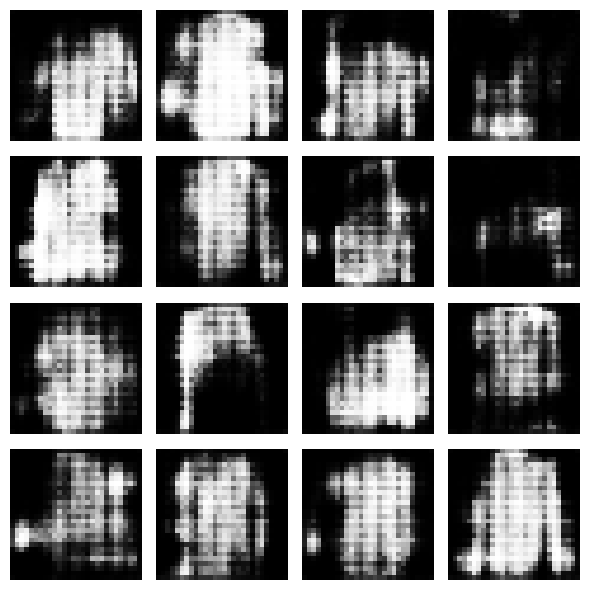

Epoch 2/20 | Generator Loss: 1.2084 | Discriminator Loss: 1.0914


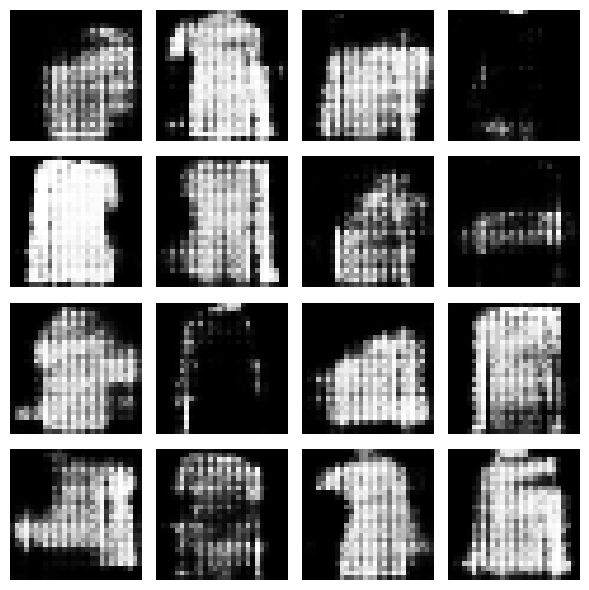

Epoch 3/20 | Generator Loss: 1.1081 | Discriminator Loss: 1.1245


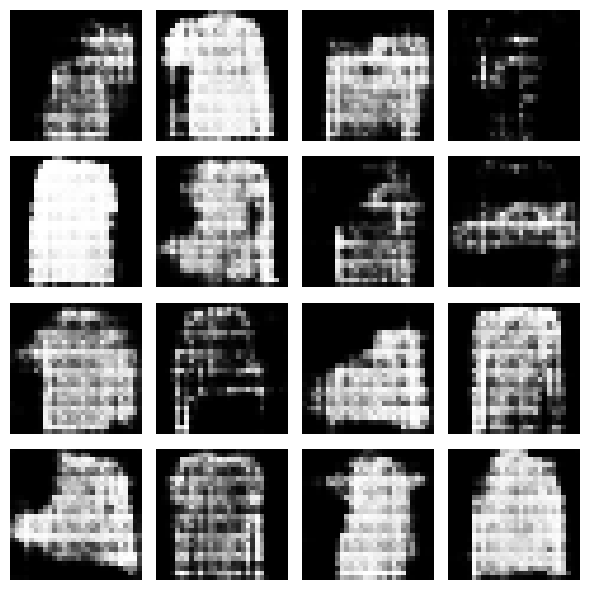

Epoch 4/20 | Generator Loss: 1.1738 | Discriminator Loss: 0.9943


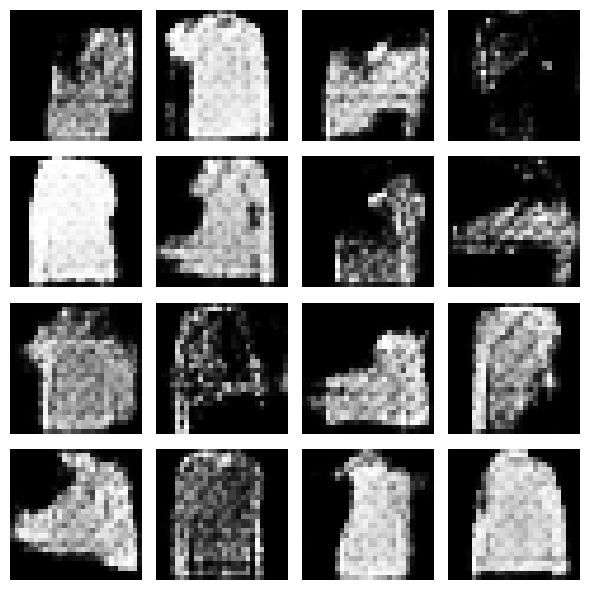

Epoch 5/20 | Generator Loss: 0.8171 | Discriminator Loss: 1.1869


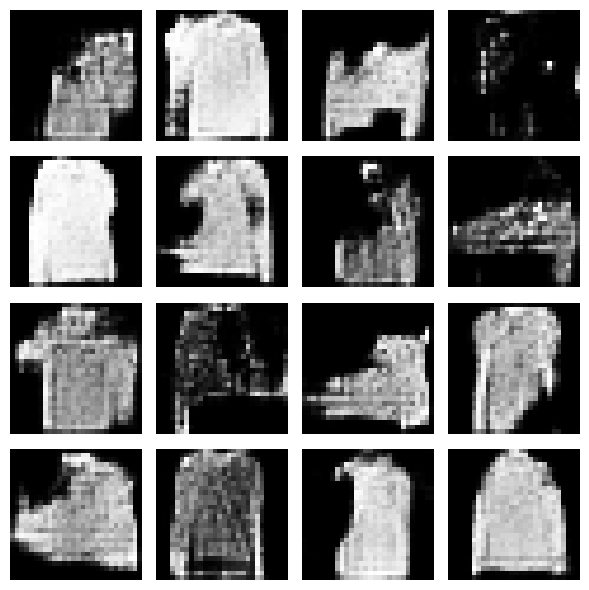

Epoch 6/20 | Generator Loss: 1.2543 | Discriminator Loss: 1.1795


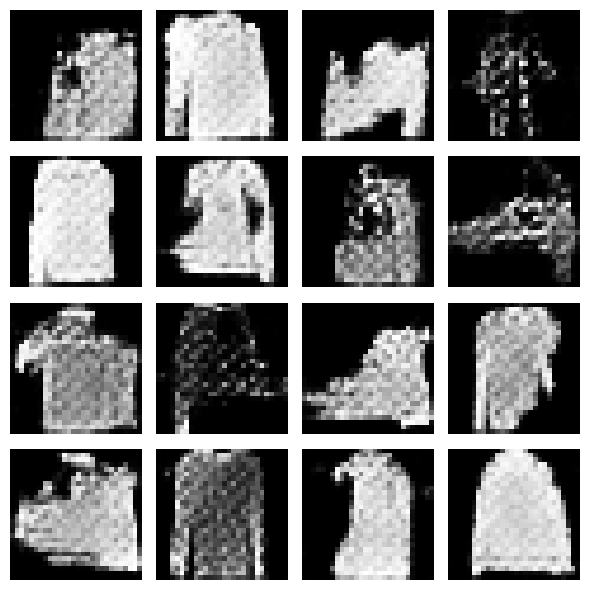

Epoch 7/20 | Generator Loss: 0.9975 | Discriminator Loss: 1.2335


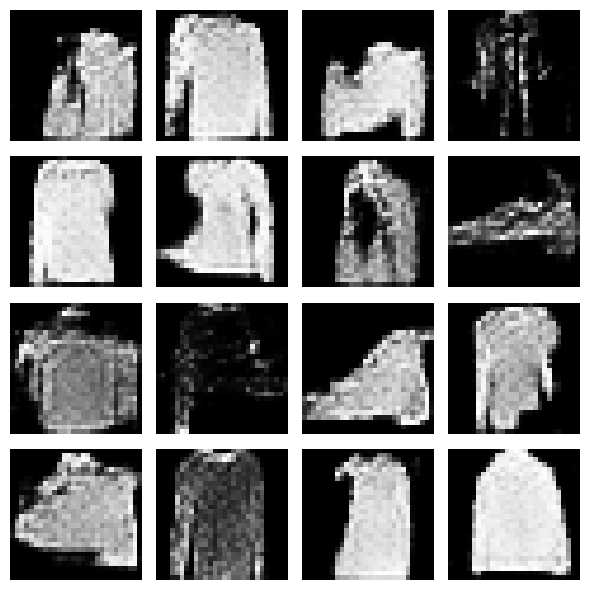

Epoch 8/20 | Generator Loss: 1.1794 | Discriminator Loss: 1.2438


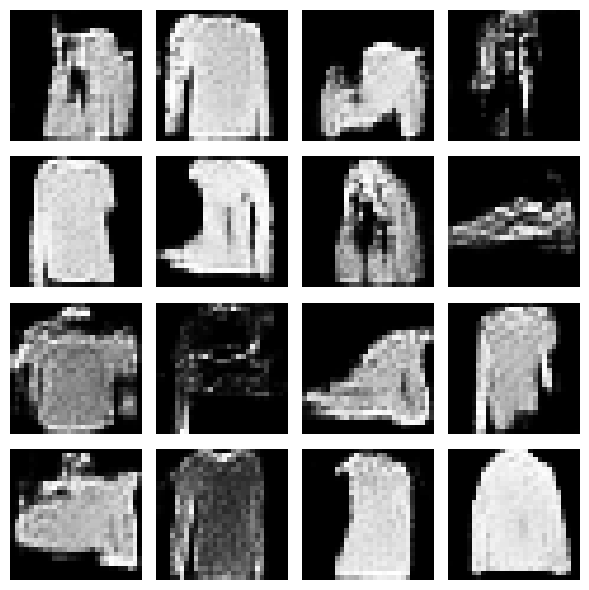

Epoch 9/20 | Generator Loss: 1.1920 | Discriminator Loss: 1.2535


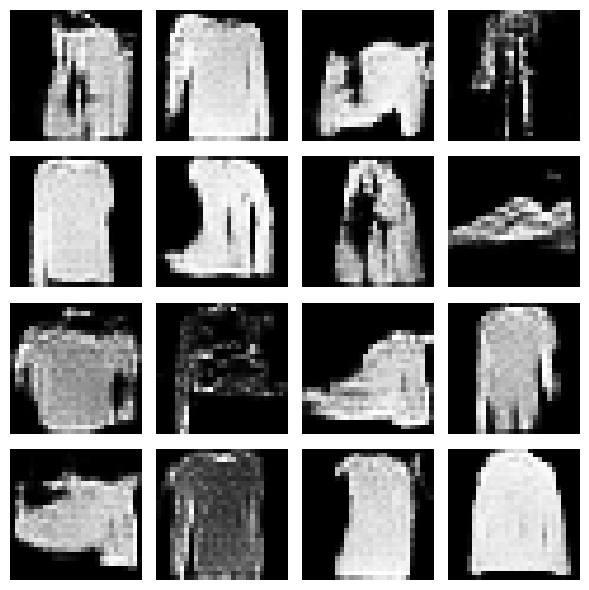

Epoch 10/20 | Generator Loss: 0.8663 | Discriminator Loss: 1.2911


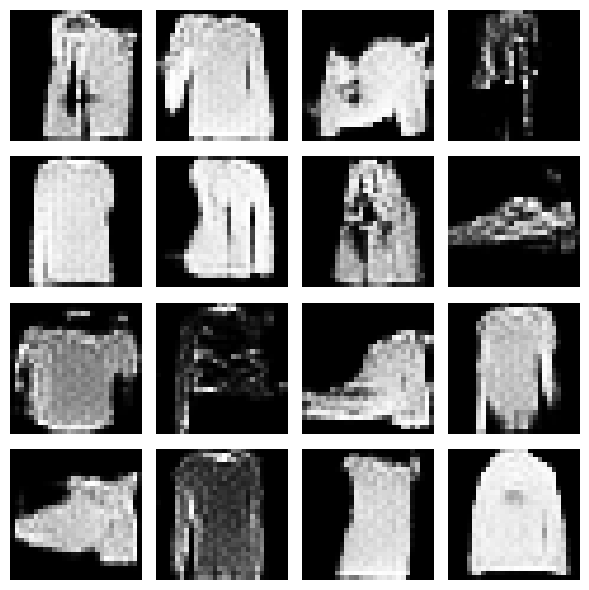

Epoch 11/20 | Generator Loss: 1.0003 | Discriminator Loss: 1.2664


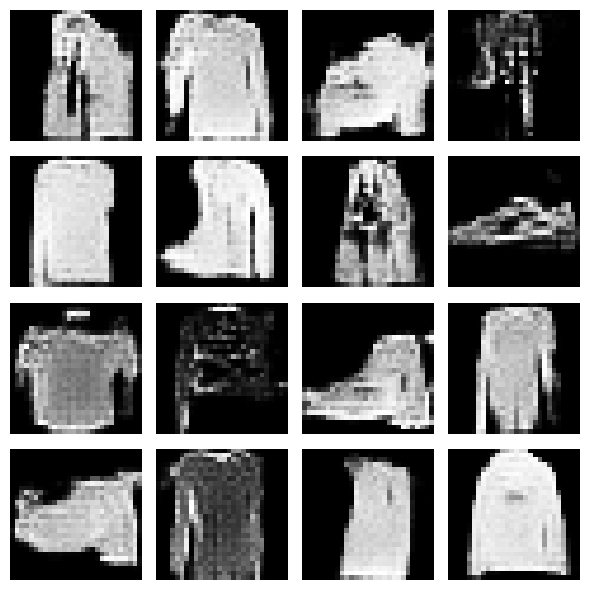

Epoch 12/20 | Generator Loss: 1.1128 | Discriminator Loss: 1.2128


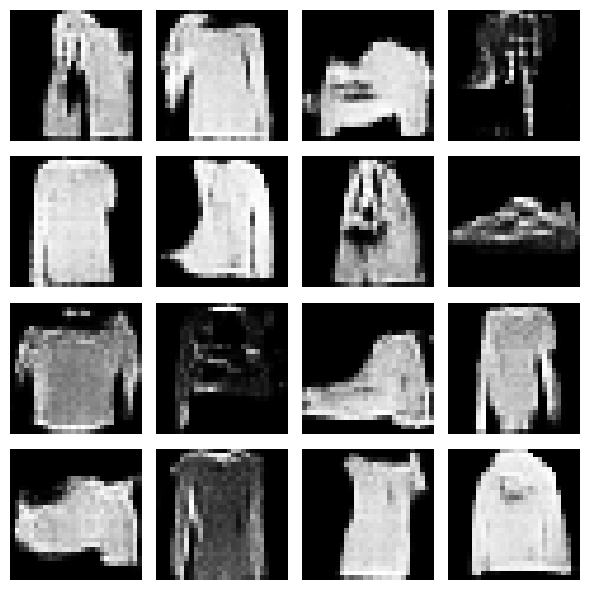

Epoch 13/20 | Generator Loss: 0.7458 | Discriminator Loss: 1.2751


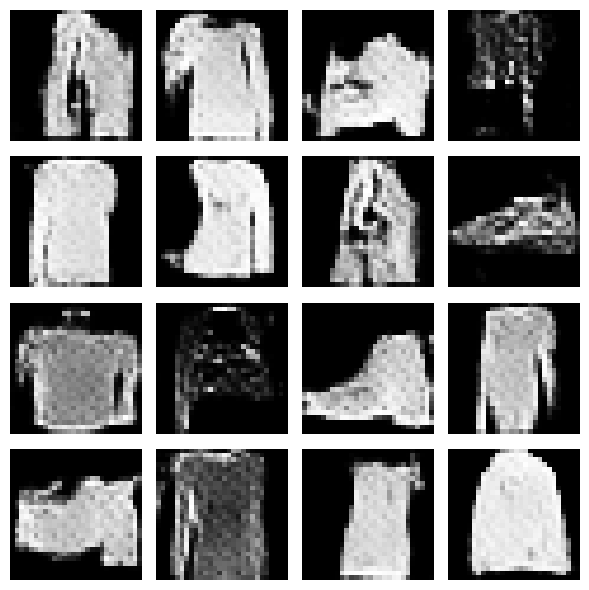

Epoch 14/20 | Generator Loss: 0.8008 | Discriminator Loss: 1.2417


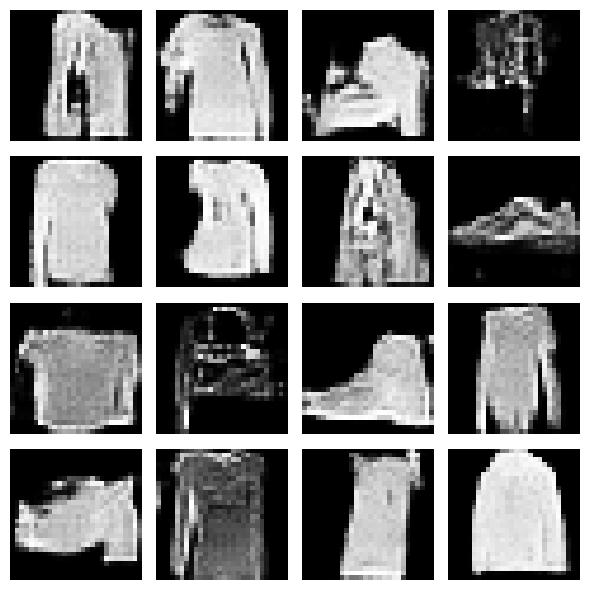

Epoch 15/20 | Generator Loss: 0.7329 | Discriminator Loss: 1.2693


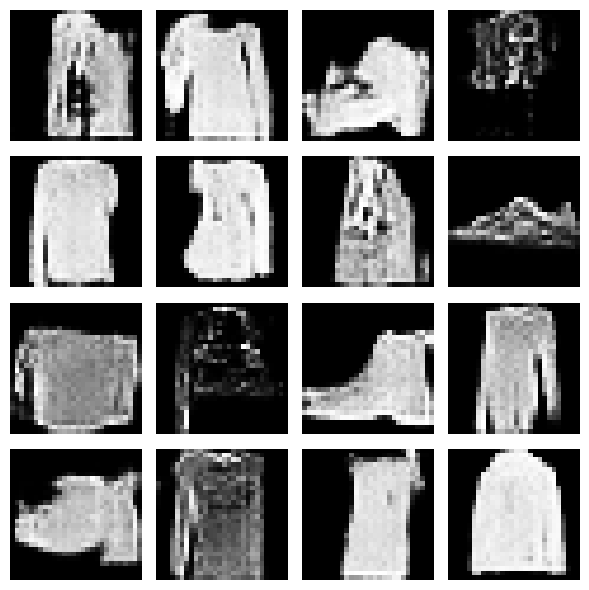

Epoch 16/20 | Generator Loss: 0.8007 | Discriminator Loss: 1.3464


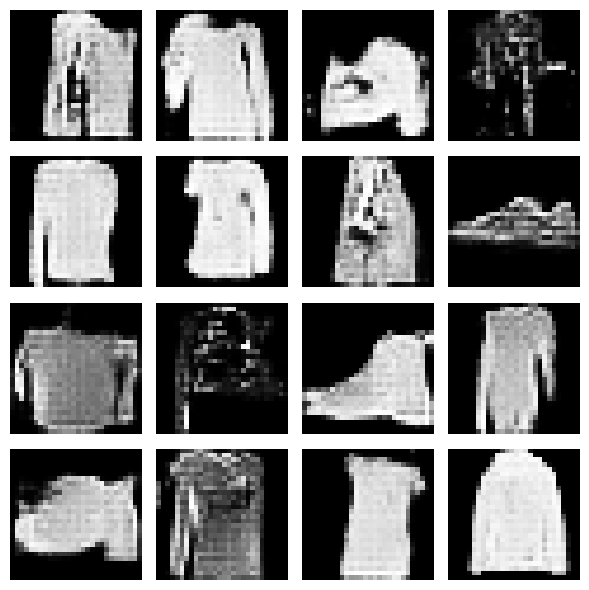

Epoch 17/20 | Generator Loss: 1.1390 | Discriminator Loss: 1.2426


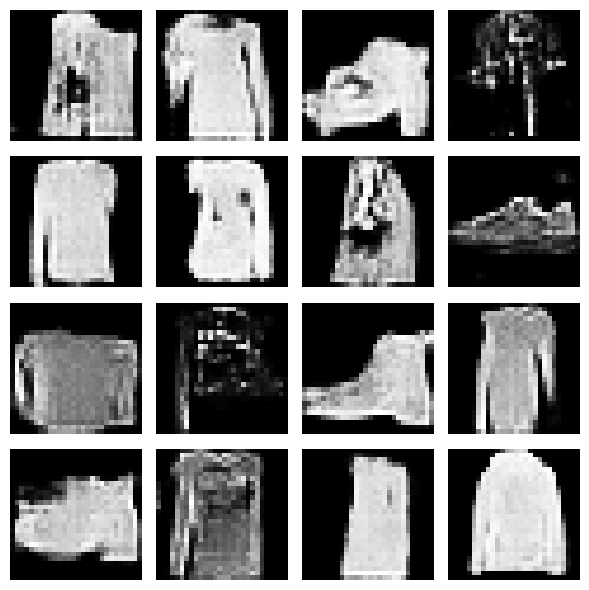

Epoch 18/20 | Generator Loss: 0.9671 | Discriminator Loss: 1.2664


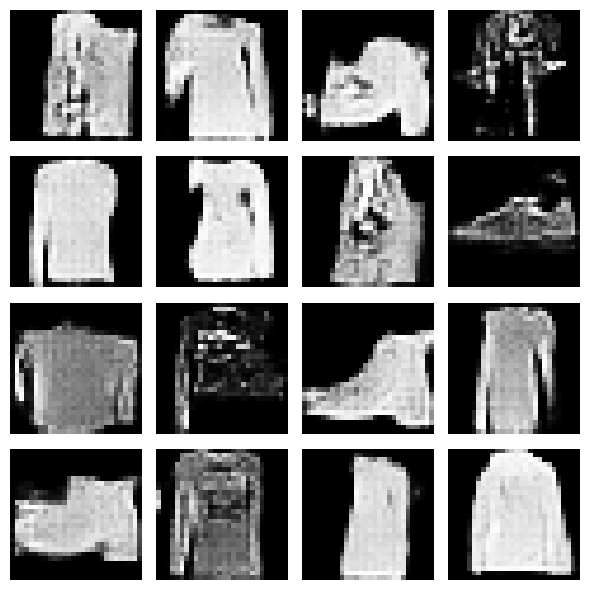

Epoch 19/20 | Generator Loss: 0.9151 | Discriminator Loss: 1.2729


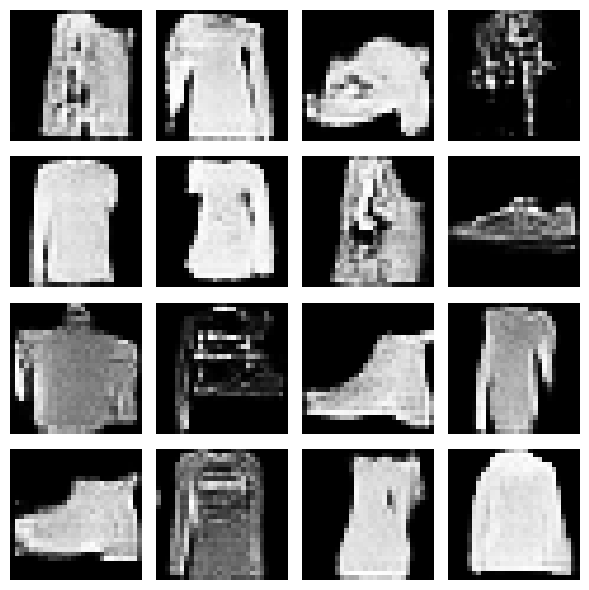

Epoch 20/20 | Generator Loss: 1.1670 | Discriminator Loss: 1.3324


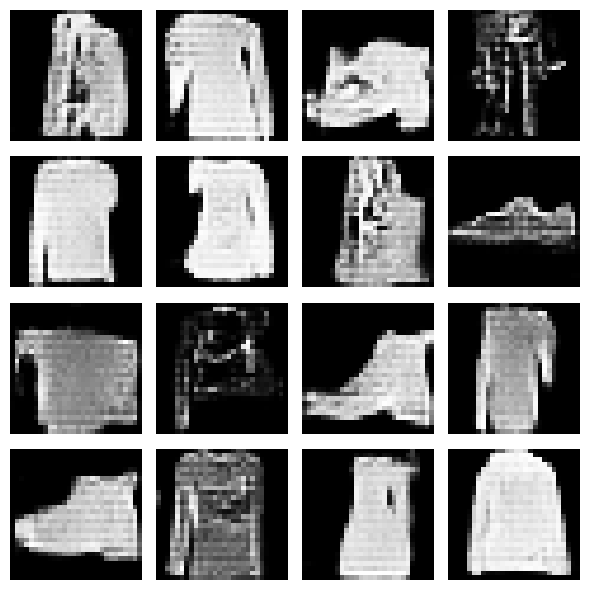

In [15]:
os.makedirs("fixed_outputs", exist_ok=True)

EPOCHS = 20

for epoch in range(EPOCHS):

    for image_batch in dataset:

        g_loss, d_loss = fixed_train_step(image_batch)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"| Generator Loss: {g_loss:.4f} "
        f"| Discriminator Loss: {d_loss:.4f}"
    )

    predictions = fixed_generator(
        seed,
        training=False
    )

    predictions = (predictions + 1) / 2.0

    fig = plt.figure(figsize=(6, 6))

    for i in range(16):
        plt.subplot(4, 4, i + 1)
        plt.imshow(
            predictions[i, :, :, 0],
            cmap="gray"
        )
        plt.axis("off")

    plt.tight_layout()

    plt.savefig(
        f"fixed_outputs/epoch_{epoch+1}.png"
    )

    plt.show()
    plt.close()

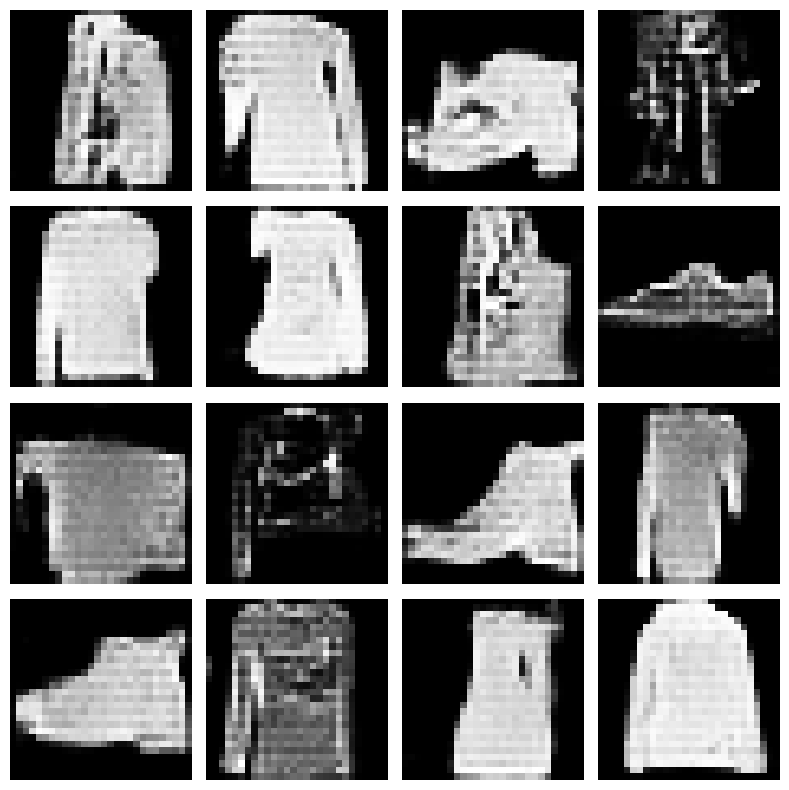

In [16]:
final_fixed = fixed_generator(
    seed,
    training=False
)

final_fixed = (final_fixed + 1) / 2.0

plt.figure(figsize=(8, 8))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    plt.imshow(
        final_fixed[i, :, :, 0],
        cmap="gray"
    )

    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "mode_collapse_after.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()